# 05-0b — La démoscène : l'intro comme argument de compression (C#)

**Navigation** : [← 05-0 : Générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [↑ 05-History](README.md) | [05-1 : DiscoDiffusion →](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb) | [Jumeau C#](05-0b-Demoscene-Intros-Procedurales-CSharp.ipynb)
**Jumeau** · [Python](05-0b-Demoscene-Intros-Procedurales-Python.ipynb)

> **Racines pré-Stable-Diffusion.** La démoscène approfondit le
> [05-0](05-0-Generateurs-Symboliques.ipynb), d'où la lettre `b` : même thèse
> (une description courte engendre un rendu riche), poussée là où une
> communauté entière en a fait un sport de compétition.

**La thèse du notebook en une ligne** : une intro de démoscène n'est pas une
vidéo compressée, c'est un **programme qui fabrique la vidéo**. Nous le
vérifions par la mesure : pour chaque effet classique, le code qui le produit
est **plus court** que ce qu'un compresseur générique (LZMA) parvient à faire
des images elles-mêmes.

**Objectifs** · Construire cinq générateurs d’images à palette indexée et comparer leur code aux flux réellement rendus et compressés.

**Prérequis** · .NET Interactive (.NET 9+), ImageMagick (`magick`), XZ Utils (`xz`) et restauration initiale de Roslyn. Ouvrir le carnet depuis son dossier.
**Durée pédagogique** · 45 min.

## 1. Un phénomène de mode des années 80-90

La démoscène naît dans les écrans d'accueil des logiciels « crackés » des
années 1980 (les *cracktros* sur Commodore 64 puis Amiga), puis s'émancipe en
une scène autonome : des groupes produisent des **démos** — animations
temps réel, son compris — et se mesurent dans des compétitions lors de
*demoparties* (Assembly en Finlande, The Party au Danemark, puis Breakpoint et
Revision en Allemagne).

Quelques jalons souvent cités, que l'on retrouve dans toute histoire de la scène :

| Production | Groupe | Année, party | Ce qu'elle montre |
|---|---|---|---|
| *Second Reality* | Future Crew | 1993, Assembly | la démo PC de référence de l'ère DOS : plasma, tunnels, rotozoom, scènes 3D |
| *fr-08: .the .product* | Farbrausch | 2000, The Party | une démo complète dans **64 ko** : textures, maillages et musique générés au lancement |
| *.kkrieger* | .theprodukkt | 2004, Breakpoint | un jeu de tir à la première personne jouable dans **96 ko** |
| *Elevated* | Rgba & TBC | 2009, Breakpoint | des paysages montagneux en **4 ko** (4096 octets) |

Les catégories de compétition (64k, 4k, et même 1k ou 256 octets) fixent une
**borne sur la taille de l'exécutable**. C'est exactement une borne sur la
longueur de description : la scène a fait de la compression un critère
esthétique, une décennie avant que Schmidhuber ne théorise le
*low-complexity art* (jalon 3 de l'Epic).

La suite du notebook rejoue les **effets canoniques** de l'ère DOS en C#, à
la résolution du mode VGA 13h (320×200, 256 couleurs indexées), et mesure à
chaque fois la longueur du programme face au poids des images.

In [1]:
#r "nuget: Microsoft.CodeAnalysis.CSharp, 4.14.0"
using System;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Text;
using System.Text.Json;
using System.Threading.Tasks;
using Microsoft.CodeAnalysis;
using Microsoft.CodeAnalysis.CSharp;
using Microsoft.CodeAnalysis.CSharp.Syntax;
using Microsoft.DotNet.Interactive.Formatting;

record FigurePng(byte[] Octets);
record FigureSvg(string Contenu);
Formatter.Register<FigurePng>((figure, writer) => writer.Write(Convert.ToBase64String(figure.Octets)), "image/png");
Formatter.SetPreferredMimeTypesFor(typeof(FigurePng), "image/png");
Formatter.Register<FigureSvg>((figure, writer) => writer.Write(figure.Contenu), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(FigureSvg), "image/svg+xml");

// Les dimensions et les coordonnées des SVG doivent rester indépendantes de la locale.
string Svg(FormattableString texte) => texte.ToString(CultureInfo.InvariantCulture);
string SvgComplet(int largeur, int hauteur, string contenu) =>
    Svg($"<svg xmlns='http://www.w3.org/2000/svg' width='{largeur}' height='{hauteur}' viewBox='0 0 {largeur} {hauteur}'><rect width='100%' height='100%' fill='white'/>{contenu}</svg>");
void AfficherPng(byte[] png, string description)
{
    Console.WriteLine(description);
    display(new FigurePng(png));
}

async Task<byte[]> AppelerOutil(string outil, byte[] entree, params string[] options)
{
    var configuration = new ProcessStartInfo(outil)
    {
        RedirectStandardInput = true,
        RedirectStandardOutput = true,
        RedirectStandardError = true,
        UseShellExecute = false
    };
    foreach (string option in options)
        configuration.ArgumentList.Add(option);

    using var processus = Process.Start(configuration)
        ?? throw new InvalidOperationException($"Impossible de démarrer {outil}.");
    using var sortie = new MemoryStream();
    // Vider les deux tubes avant de pousser l'entrée évite un blocage du compresseur ou du rasteriseur.
    var lecture = processus.StandardOutput.BaseStream.CopyToAsync(sortie);
    var diagnostic = processus.StandardError.ReadToEndAsync();
    await processus.StandardInput.BaseStream.WriteAsync(entree);
    processus.StandardInput.Close();
    await Task.WhenAll(lecture, diagnostic, processus.WaitForExitAsync());
    if (processus.ExitCode != 0)
        throw new InvalidOperationException($"{outil} ({processus.ExitCode}) : {await diagnostic}");
    return sortie.ToArray();
}

byte[] LireDeclarations(string carnet, params string[] noms)
{
    // Mesurer le code propre au carnet, en excluant la prose et les appels à ces fonctions.
    using var document = JsonDocument.Parse(File.ReadAllText(carnet));
    var declarations = new Dictionary<string, string>(StringComparer.Ordinal);
    var options = CSharpParseOptions.Default.WithKind(SourceCodeKind.Script);
    foreach (var cellule in document.RootElement.GetProperty("cells").EnumerateArray())
    {
        if (cellule.GetProperty("cell_type").GetString() != "code")
            continue;
        var source = cellule.GetProperty("source");
        string texte = source.ValueKind == JsonValueKind.Array
            ? string.Concat(source.EnumerateArray().Select(ligne => ligne.GetString()))
            : source.GetString()!;
        var racine = CSharpSyntaxTree.ParseText(texte, options).GetRoot();
        foreach (var noeud in racine.DescendantNodes())
        {
            string nom = noeud switch
            {
                MethodDeclarationSyntax methode => methode.Identifier.ValueText,
                LocalFunctionStatementSyntax fonction => fonction.Identifier.ValueText,
                _ => ""
            };
            if (noms.Contains(nom) && !declarations.TryAdd(nom, noeud.ToFullString().TrimEnd()))
                throw new InvalidOperationException($"Déclaration en double : {nom}.");
        }
    }
    return Encoding.UTF8.GetBytes(string.Join("\n", noms.Select(nom => declarations[nom])));
}

Task<byte[]> Compresser(byte[] donnees, string niveau) =>
    AppelerOutil("xz", donnees, niveau, "--threads=1", "--check=crc64", "--stdout");

// Un vrai aller-retour XZ et un PNG 4×4 valident les deux moteurs avant les mesures.
var temoin = Encoding.UTF8.GetBytes("une description, un rendu");
var temoinXz = await Compresser(temoin, "-1");
var temoinRelu = await AppelerOutil("xz", temoinXz, "--decompress", "--stdout");
var temoinPng = await AppelerOutil("magick", Encoding.ASCII.GetBytes("P2\n2 2\n255\n0 255 255 0\n"), "pgm:-", "png:-");
if (!temoinRelu.SequenceEqual(temoin) || !temoinPng.Take(8).SequenceEqual(new byte[] {137, 80, 78, 71, 13, 10, 26, 10}))
    throw new InvalidOperationException("Le témoin XZ ou PNG ne passe pas.");
Console.WriteLine($"Témoins moteurs : {temoin.Length} octets relus après XZ, PNG {temoinPng.Length} octets.");

Installed Packages Microsoft.CodeAnalysis.CSharp, 4.14.0

Témoins moteurs : 25 octets relus après XZ, PNG 252 octets.


### Préparer le rendu et les mesures

Le témoin confirme qu’un flux XZ se décompresse et qu’ImageMagick produit un PNG. Roslyn extrait les déclarations C# de ce fichier pour que leur description soit mesurée à chaque exécution.

In [2]:
const int Largeur = 320, Hauteur = 200, NombreTrames = 64;
const string Carnet = "05-0b-Demoscene-Intros-Procedurales-CSharp.ipynb";
var indicesMontage = new[] { 0, 16, 32, 48 };
var paletteDemo = Enumerable.Range(0, 256).Select(i =>
{
    double phase = 2 * Math.PI * i / 256;
    return (R: (byte)(127.5 + 127.5 * Math.Sin(phase)),
            G: (byte)(127.5 + 127.5 * Math.Sin(phase + 2.1)),
            B: (byte)(127.5 + 127.5 * Math.Sin(phase + 4.2)));
}).ToArray();
// La palette « bone » combine gris et hot inversé, avec un poids de 1/8 pour la teinte.
var paletteBone = Enumerable.Range(0, 256).Select(i =>
{
    double n = i / 255.0;
    double chaud(double niveau) => Math.Clamp(niveau, 0, 1);
    return (R: (byte)(255 * (7 * n + chaud((n - 0.746) / 0.254)) / 8),
            G: (byte)(255 * (7 * n + chaud((n - 0.365) / 0.381)) / 8),
            B: (byte)(255 * (7 * n + chaud(n / 0.365)) / 8));
}).ToArray();
var paletteFeu = Enumerable.Range(0, 256).Select(i =>
{
    byte canal(int rang) => (byte)Math.Clamp(3 * (i - 85 * rang), 0, 255);
    return (R: canal(0), G: canal(1), B: canal(2));
}).ToArray();
byte[] Trame(int largeur, int hauteur, Func<int, int, byte> pixel)
{
    var trame = new byte[largeur * hauteur];
    // Un octet par pixel, rangées successives comme le tableau contigu NumPy.
    for (int y = 0; y < hauteur; y++)
        for (int x = 0; x < largeur; x++)
            trame[y * largeur + x] = pixel(x, y);
    return trame;
}
async Task Vue(byte[][] trames, int l, int h, (byte R, byte G, byte B)[] palette, string titre)
{
    int largeurMontage = l * indicesMontage.Length;
    byte[] entete = Encoding.ASCII.GetBytes($"P6\n{largeurMontage} {h}\n255\n");
    var ppm = new byte[entete.Length + 3 * largeurMontage * h];
    entete.CopyTo(ppm, 0);
    for (int y = 0; y < h; y++)
        for (int panneau = 0; panneau < indicesMontage.Length; panneau++)
        {
            var trame = trames[indicesMontage[panneau]];
            for (int x = 0; x < l; x++)
            {
                var (r, v, b) = palette[trame[y * l + x]];
                int d = entete.Length + 3 * (y * largeurMontage + panneau * l + x);
                ppm[d] = r;
                ppm[d + 1] = v;
                ppm[d + 2] = b;
            }
        }
    var png = await AppelerOutil("magick", ppm, "ppm:-", "png:-");
    AfficherPng(png, $"{titre}, de gauche à droite t = 0, 16, 32, 48");
}
Console.WriteLine($"VGA {Largeur} × {Hauteur}, {NombreTrames} trames, {Largeur * Hauteur * NombreTrames:N0} octets bruts par effet à pleine résolution.");

VGA 320 × 200, 64 trames, 4,096,000 octets bruts par effet à pleine résolution.


## 2. Le plasma : une somme de sinus et une palette

Le **plasma** est l'effet emblématique de l'ère DOS. Chaque pixel reçoit une
somme de sinus de ses coordonnées et du temps ; l'animation vient du terme
temporel et, à l'époque, souvent du simple **cycle de palette** (faire tourner
la table des couleurs sans toucher aux pixels). Aucune image n'est stockée :
la fonction est l'image.

Plasma — quatre sinusoïdes, de gauche à droite t = 0, 16, 32, 48


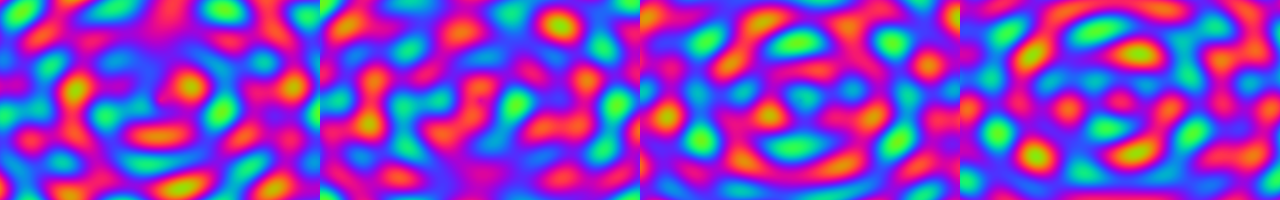

In [3]:
byte[] Plasma(int t) => Trame(Largeur, Hauteur, (x, y) =>
{
    // Quatre fréquences spatiales et temporelles alimentent directement l'indice de palette.
    double dx = x - Largeur / 2.0, dy = y - Hauteur / 2.0;
    double phase = Math.Sin(x / 16.0 + t / 8.0) + Math.Sin(y / 8.0 + t / 12.0)
        + Math.Sin((x + y + t) / 16.0) + Math.Sin(Math.Sqrt(dx * dx + dy * dy) / 8 - t / 6.0);
    return (byte)((phase + 4) * 32);
});
var tramesPlasma = Enumerable.Range(0, NombreTrames).Select(Plasma).ToArray();
await Vue(tramesPlasma, Largeur, Hauteur, paletteDemo, "Plasma — quatre sinusoïdes");

### Interprétation : quatre sinus suffisent

La palette cyclique traduit quatre ondes en contours. Les quatre panneaux montrent la même règle
aux instants 0, 16, 32 et 48. La séquence complète demande 320×200×64 = 4 096 000 octets
en indices VGA. La cellule de configuration calcule ce poids avant toute compression.

## 3. Le tunnel : deux tables précalculées et une texture

Le **tunnel** est l'archétype du *précalcul* démoscénique : pour chaque pixel
on calcule une seule fois sa distance au centre et son angle, qui deviennent
des coordonnées de texture. À chaque frame, il ne reste qu'à **décaler** ces
coordonnées : le coût par frame tombe à une lecture de table, ce qui rendait
l'effet fluide sur un 486. La texture elle-même est générée (un motif XOR,
autre classique de l'époque).

Tunnel — distance et angle, de gauche à droite t = 0, 16, 32, 48


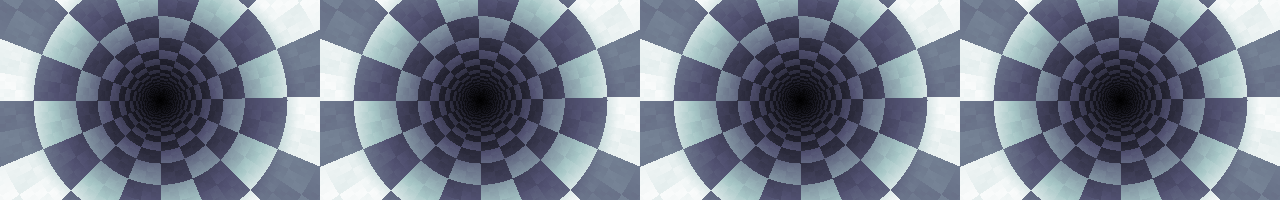

In [4]:
byte[] Tunnel(int t) => Trame(Largeur, Hauteur, (x, y) =>
{
    double dx = x - Largeur / 2.0, dy = y - Hauteur / 2.0;
    double rayon = Math.Sqrt(dx * dx + dy * dy) + 1;
    // Dans ces coordonnées polaires la profondeur varie avec l'inverse de la distance.
    int u = (int)(4096 / rayon) + 4 * t;
    int v = (int)(128 * Math.Atan2(dy, dx) / Math.PI) + 2 * t;
    int damier = ((u >> 4) ^ (v >> 4)) & 1;
    int texture = 120 + 100 * damier + ((u ^ v) & 31);
    return (byte)(texture * Math.Clamp(rayon / 140, 0, 1));
});
var tramesTunnel = Enumerable.Range(0, NombreTrames).Select(Tunnel).ToArray();
await Vue(tramesTunnel, Largeur, Hauteur, paletteBone, "Tunnel — distance et angle");

### Interprétation : la perspective vient d'une division

On voit un couloir qui file vers le centre : les cases du damier s'écrasent
en anneaux de plus en plus serrés près du point de fuite, et le noir central
donne la profondeur. Toute la perspective tient dans la division `4096 / r` :
un pixel proche du centre lit une case « lointaine ». D'une frame à l'autre,
la texture glisse (terme `4 * t` sur la profondeur, `2 * t` sur l'angle) et
le tunnel semble avancer en tournant. L'assombrissement exige une palette
**monotone** (ici du noir au blanc) : avec la palette cyclique du plasma,
multiplier un indice par `ombre` ne l'assombrirait pas, il changerait sa teinte.

## 4. Le feu : un automate cellulaire déguisé

L'effet **feu** est un cousin direct des automates du [05-0](05-0-Generateurs-Symboliques.ipynb) :
on allume aléatoirement la ligne du bas, puis chaque pixel devient la moyenne
de ses voisins du dessous, légèrement refroidie. La règle est **locale** et
appliquée partout : c'est un automate cellulaire à états continus. Le hasard
est piloté par une graine, qui fait partie de la description.

Feu — automate à chauffe initiale, de gauche à droite t = 0, 16, 32, 48


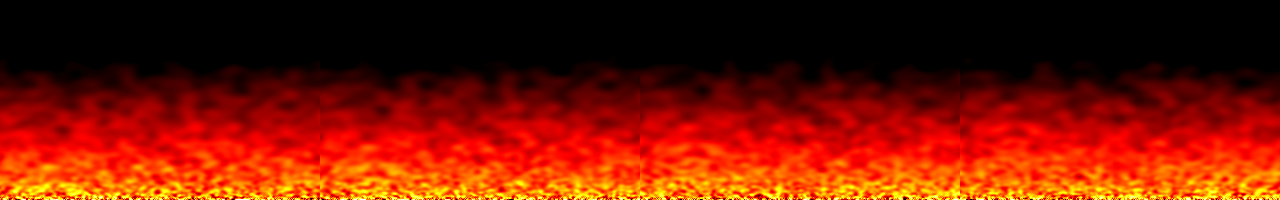

In [5]:
byte[][] Feu(int nombre, int graine = 1993)
{
    var hasard = new Random(graine);
    var grille = new float[(Hauteur + 2) * Largeur];
    var suivant = new float[grille.Length];
    var trames = new byte[nombre][];
    const int chauffe = 200;
    for (int t = 0; t < nombre + chauffe; t++)
    {
        for (int i = Hauteur * Largeur; i < grille.Length; i++)
            grille[i] = hasard.NextDouble() < 0.55 ? 255 : 0;
        // Chaque cellule lit l'ancienne grille, même quand les rangées sont traversées dans l'ordre.
        for (int y = 0; y < Hauteur; y++)
        {
            int baseProche = (y + 1) * Largeur;
            for (int x = 0; x < Largeur; x++)
            {
                int gauche = (x + Largeur - 1) % Largeur;
                int droite = (x + 1) % Largeur;
                float moyenne = (grille[baseProche + Largeur + x] + grille[baseProche + gauche]
                    + grille[baseProche + x] + grille[baseProche + droite]) / 4;
                suivant[y * Largeur + x] = Math.Max(moyenne - 1.3f, 0);
            }
        }
        (grille, suivant) = (suivant, grille);
        if (t >= chauffe)
            trames[t - chauffe] = Trame(Largeur, Hauteur, (x, y) => (byte)grille[y * Largeur + x]);
    }
    return trames;
}
var tramesFeu = Feu(NombreTrames);
await Vue(tramesFeu, Largeur, Hauteur, paletteFeu, "Feu — automate à chauffe initiale");

### Interprétation : flammes, sans une ligne sur les flammes

Les flammes montent depuis le bas de l'écran et s'éteignent vers le haut,
avec des langues irrégulières différentes à chaque frame. Le code ne dit rien
des flammes : il dit seulement « allume le bas au hasard, puis fais la moyenne
des voisins en refroidissant un peu » (le terme `- 1.3`). La hauteur des
flammes est fixée par ce seul refroidissement : plus il est fort, plus le feu
s'éteint bas. La
forme émerge de la règle locale, exactement comme le planeur du Game of Life ;
la palette noir → rouge → jaune → blanc fait le reste.

Le générateur `Random` de .NET et le générateur de NumPy produisent des séries différentes à graine nominale égale. Le taux de braises, la grille, la chauffe et la règle locale sont communs.

## 5. Le rotozoom : une texture, une matrice

Le **rotozoomer** applique à chaque frame une rotation et un facteur d'échelle
à une texture répétée à l'infini. Sur Amiga et PC, c'était l'effet
« impossible » du début des années 90 : il exige de recalculer chaque pixel à
chaque frame, d'où des boucles internes en assembleur réduites à deux
additions par pixel. En C#, c'est une transformation affine des
coordonnées.

Rotozoom — une texture périodique, de gauche à droite t = 0, 16, 32, 48


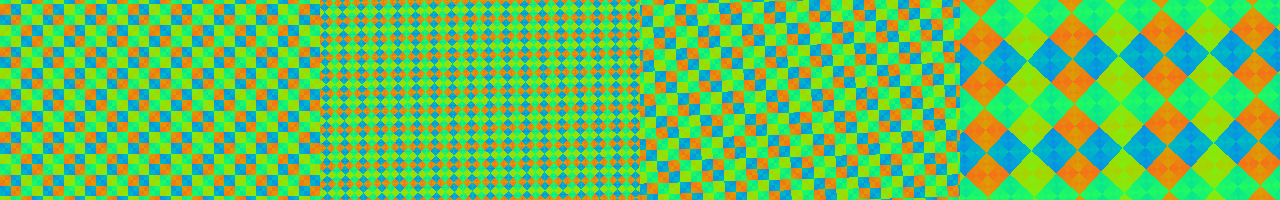

In [6]:
byte[] Rotozoom(int t)
{
    double angle = t / 20.0, zoom = 1.5 + Math.Sin(t / 10.0);
    double c = Math.Cos(angle), s = Math.Sin(angle);
    return Trame(Largeur, Hauteur, (x, y) =>
    {
        // Rotation et échelle se composent avant l'échantillonnage du damier infini.
        double dx = x - Largeur / 2.0, dy = y - Hauteur / 2.0;
        int u = (int)((dx * c - dy * s) * zoom);
        int v = (int)((dx * s + dy * c) * zoom);
        int damier = ((u >> 4) ^ (v >> 4)) & 1;
        return (byte)(damier * 160 + ((u ^ v) & 63));
    });
}
var tramesRoto = Enumerable.Range(0, NombreTrames).Select(Rotozoom).ToArray();
await Vue(tramesRoto, Largeur, Hauteur, paletteDemo, "Rotozoom — une texture périodique");

### Interprétation : le mouvement est dans la matrice

Les quatre frames montrent le même damier texturé, tourné d'un angle
croissant et zoomé selon un sinus : l'image ne change pas, c'est le **repère**
qui bouge. Le coût de l'effet est proportionnel au nombre de pixels et non à
la complexité de la texture, d'où son attrait à l'époque : une seule
transformation donne l'illusion d'une caméra libre au-dessus d'un sol infini.

## 6. Le raymarching : la scène 4k des années 2000

À partir des années 2000, les intros 4k basculent sur le GPU et une technique
domine : le **raymarching de champs de distance signée** (*signed distance
fields*, SDF), popularisé dans la scène par Iñigo Quílez (Rgba, coauteur
d'*Elevated*). La scène n'est plus une liste de triangles mais une **fonction**
qui rend, pour tout point de l'espace, sa distance à la surface la plus proche.
On avance le long de chaque rayon d'un pas égal à cette distance, en sécurité,
jusqu'à toucher la surface.

Ci-dessous, une scène complète (sol, sphères répétées à l'infini par un
modulo, éclairage diffus et ombre portée de brouillard) en une trentaine de
lignes, rendue sur CPU à demi-résolution pour rester raisonnable.

64 trames raymarchées en 8.21 s (CPU, 160 × 100).


Raymarching — sol et sphères répétées, de gauche à droite t = 0, 16, 32, 48


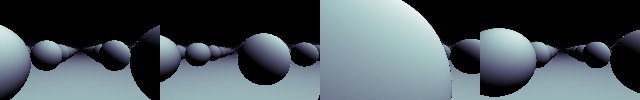

In [7]:
float SceneSdf(float x, float y, float z)
{
    // Floor donne le modulo positif de NumPy, y compris pour la caméra en coordonnées négatives.
    float cx = x - 4 * MathF.Floor(x / 4) - 2;
    float cz = z - 4 * MathF.Floor(z / 4) - 2;
    float cy = y - 0.2f;
    return Math.Min(y + 1, MathF.Sqrt(cx * cx + cy * cy + cz * cz) - 0.9f);
}
byte[] Raymarch(float t, int largeur = Largeur / 2, int hauteur = Hauteur / 2, int pas = 64)
{
    float ox = 0.3f * t, oy = 0.5f, oz = 0.6f * t;
    return Trame(largeur, hauteur, (x, y) =>
    {
        float dx = (x - largeur / 2f) / hauteur, dy = -(y - hauteur / 2f) / hauteur;
        float norme = MathF.Sqrt(dx * dx + dy * dy + 1);
        dx /= norme;
        dy /= norme;
        float dz = 1 / norme, distance = 0;
        // Conserver les 64 marches pour tous les pixels, comme dans l'expérience de départ.
        for (int k = 0; k < pas; k++)
            distance += SceneSdf(ox + dx * distance, oy + dy * distance, oz + dz * distance);
        float px = ox + dx * distance, py = oy + dy * distance, pz = oz + dz * distance;
        const float e = 1e-3f;
        float gx = SceneSdf(px + e, py, pz) - SceneSdf(px - e, py, pz);
        float gy = SceneSdf(px, py + e, pz) - SceneSdf(px, py - e, pz);
        float gz = SceneSdf(px, py, pz + e) - SceneSdf(px, py, pz - e);
        // La normale par différences finies sépare le modèle de scène de l'éclairage.
        float gn = MathF.Sqrt(gx * gx + gy * gy + gz * gz) + 1e-9f;
        float lumiere = Math.Clamp((gx * 0.5f + gy * 0.8f - gz * 0.3f) / gn, 0, 1);
        return (byte)(255 * lumiere * MathF.Exp(-0.04f * distance));
    });
}
var chrono = Stopwatch.StartNew();
var tramesSdf = Enumerable.Range(0, NombreTrames).Select(t => Raymarch(t / 4f)).ToArray();
Console.WriteLine($"{tramesSdf.Length} trames raymarchées en {chrono.Elapsed.TotalSeconds:F2} s (CPU, {Largeur / 2} × {Hauteur / 2}).");
await Vue(tramesSdf, Largeur / 2, Hauteur / 2, paletteBone, "Raymarching — sol et sphères répétées");

### Interprétation : une scène infinie décrite par un `min`

Les frames montrent une forêt de sphères alignées à perte de vue sur un sol,
éclairées par le haut et noyées dans le brouillard au loin ; la caméra avance
d'une frame à l'autre. Tout tient dans `scene_sdf` : le `min` fait l'union
des objets et le modulo répète les sphères **à l'infini** sans en stocker
aucune. C'est la forme moderne de la thèse du jalon : une scène dont la
description fait quelques centaines d'octets et dont le rendu n'a pas de
borne. Le temps de calcul affiché (CPU, C#) rappelle pourquoi ces intros
ciblent le GPU, où le même code tourne par pixel en parallèle.

## 7. La mesure : le programme contre le compresseur

C'est la leçon exécutable du jalon. Pour chaque effet, on compare trois
grandeurs :

- **le rendu brut** : la séquence de 64 frames, un octet par pixel ;
- **les frames compressées par LZMA** (`preset=9 | PRESET_EXTREME`) : ce que
  fait un bon compresseur générique, qui ne sait rien de la façon dont les
  images ont été produites ;
- **le programme compressé** : le code source de la fonction d'effet, lui
  aussi passé par LZMA. C'est l'équivalent du *packer* d'exécutable des
  intros 4k et 64k.

**Ce que la mesure compte, et ce qu'elle ne compte pas.** La cellule
mesure uniquement la **source des noyaux** (syntaxe Roslyn pour
chaque fonction d'effet), et le ratio `frames brutes / source compressée` est ce
qui figure dans la colonne `brut/prog` du tableau ci-dessous — c'est la
**borne haute** de la section. La colonne `xz/prog` (frames compressées /
programme compressé) en donne la version **conservatrice**, et c'est elle que
commente la mesure principale. Sont **exclus explicitement** de la
mesure :

- les **dimensions** `Largeur` et `Hauteur` de l'image (320×200 pour plasma / tunnel / feu / rotozoom, et 160×100 pour le raymarching rendu à demi-résolution, comme annoncé en section 6).
- les **coordonnées et offsets** : `x`, `y` (positions initiales,
  déphasages, centres de rotation) ;
- la **palette** de couleurs (les LUT et gradients) ;
- les **paramètres** algorithmiques (vitesses, amplitudes, fréquences,
  coefficients d'amortissement) ;
- l'**assemblage** de la fonction (imports, fermetures, environnement
  d'appel, conditions initiales) ;
- le **runtime .NET et les utilitaires de rendu** — une intro réelle ne
  les a pas non plus (elle s'appuie sur le système, les pilotes et
  parfois DirectX ou OpenGL, mais doit embarquer tout le reste).

Le chiffre mesure donc une description **relative à un langage, une
palette et un jeu de paramètres donnés** : le ratio dépend de la
représentation choisie, sans invariance ni borne de complexité
démontrée. La mesure n'établit rien sur la complexité d'un effet
**arbitraire** en dehors de l'instance précise mesurée — c'est ce
que la section 8 vérifie empiriquement en faisant varier le nombre
de frames.

In [8]:
var effets = new (string Nom, byte[][] Trames, string[] Fonctions)[]
{
    ("plasma", tramesPlasma, new[] { nameof(Plasma) }),
    ("tunnel", tramesTunnel, new[] { nameof(Tunnel) }),
    ("feu", tramesFeu, new[] { nameof(Feu) }),
    ("rotozoom", tramesRoto, new[] { nameof(Rotozoom) }),
    ("raymarching", tramesSdf, new[] { nameof(SceneSdf), nameof(Raymarch) })
};
byte[] Aplatir(byte[][] trames)
{
    // Le compresseur reçoit les indices VGA, pas des captures déjà compressées ni les palettes.
    int taille = trames[0].Length;
    var flux = new byte[taille * trames.Length];
    for (int i = 0; i < trames.Length; i++)
        trames[i].CopyTo(flux, i * taille);
    return flux;
}
Console.WriteLine($"{"Effet",-13} {"source",8} {"source.xz",11} {"brut",11} {"trames.xz",11} {"brut/prog",10} {"xz/prog",9}");
var mesuresEffets = new List<(string Nom, int Texte, int Programme, int Brut, int Xz)>();
foreach (var (nom, trames, fonctions) in effets)
{
    byte[] source = LireDeclarations(Carnet, fonctions), flux = Aplatir(trames);
    byte[] code = await Compresser(source, "-9e"), rendu = await Compresser(flux, "-9e");
    if (trames.Length != NombreTrames || flux.Length != (nom == "raymarching" ? 1024000 : 4096000))
        throw new InvalidOperationException($"Budget de trames invalide pour {nom}.");
    mesuresEffets.Add((nom, source.Length, code.Length, flux.Length, rendu.Length));
    Console.WriteLine($"{nom,-13} {source.Length,8:N0} {code.Length,11:N0} {flux.Length,11:N0} {rendu.Length,11:N0} {(double)flux.Length / code.Length,10:N0} {(double)rendu.Length / code.Length,9:F1}");
}

Effet           source   source.xz        brut   trames.xz  brut/prog   xz/prog


plasma             428         344   4,096,000   1,092,412     11,907    3175.6


tunnel             527         404   4,096,000     401,468     10,139     993.7


feu              1,268         612   4,096,000     920,540      6,693    1504.2


rotozoom           551         384   4,096,000     660,928     10,667    1721.2


raymarching      1,652         768   1,024,000     137,636      1,333     179.2


### Interprétation : le générateur bat le compresseur

Le tableau compare cinq séquences véritables. La colonne « brut/prog » compte les indices
VGA sans compression. La colonne « xz/prog » compare deux sorties du même compresseur
et montre ce que le modèle spécifique de chaque effet économise encore. Le raymarching
utilise une demi-résolution et deux déclarations, ce qui influe sur son rapport.
Le feu tire des braises aléatoires, le tunnel répète des motifs du damier ; ces deux
organisations donnent des redondances différentes au compresseur.

Le programme mesuré contient seulement les fonctions génératrices. Les dimensions, la
boucle d’affichage, la palette et le runtime sont partagés et exclus du compte. Les
rapports sont donc une expérience sur ces effets, avec un instrument précis, et ne
prédisent pas la taille d’un exécutable de concours.

## 8. Le ratio grandit avec la durée

Un dernier contrôle rend la thèse quantitative. La description d'un effet est
**constante** ; le rendu, lui, croît avec le nombre de frames
— c'est l'observation conduite sur 8 à 128 frames en §8, pas une loi
générale au-delà de ce domaine.
LZMA, de son côté, profite de la ressemblance entre frames successives, mais
doit tout de même encoder ce qui change. On mesure les deux sur le plasma pour
des séquences de plus en plus longues.

  8 trames | brut   512,000 o | trames.xz  161,992 o | programme.xz 344 o | rapport 470.9


 16 trames | brut 1,024,000 o | trames.xz  301,252 o | programme.xz 344 o | rapport 875.7


 32 trames | brut 2,048,000 o | trames.xz  572,404 o | programme.xz 344 o | rapport 1664.0


 64 trames | brut 4,096,000 o | trames.xz 1,092,412 o | programme.xz 344 o | rapport 3175.6


128 trames | brut 8,192,000 o | trames.xz 2,086,908 o | programme.xz 344 o | rapport 6066.6


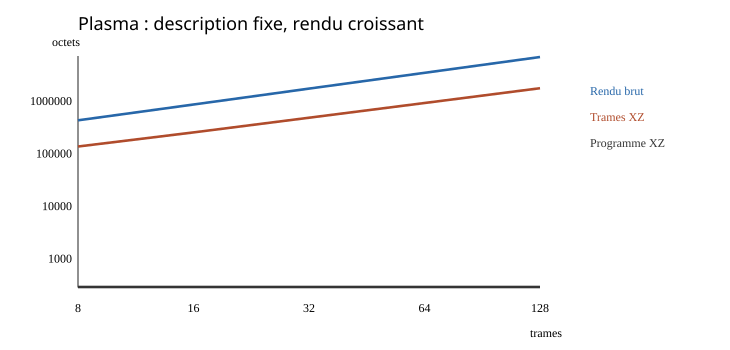

In [9]:
var durees = new[] { 8, 16, 32, 64, 128 };
int programmePlasma = (await Compresser(LireDeclarations(Carnet, nameof(Plasma)), "-9e")).Length;
var balayage = new List<(int N, int Brut, int Xz)>();
foreach (int n in durees)
{
    var flux = Aplatir(Enumerable.Range(0, n).Select(Plasma).ToArray());
    int compresse = (await Compresser(flux, "-9e")).Length;
    balayage.Add((n, flux.Length, compresse));
    Console.WriteLine($"{n,3} trames | brut {flux.Length,9:N0} o | trames.xz {compresse,8:N0} o | programme.xz {programmePlasma} o | rapport {(double)compresse / programmePlasma:F1}");
}
// Les axes logarithmiques rendent comparables la source fixe et les deux flux de tailles très différentes.
double PosX(int n) => 78 + 462 * Math.Log2(n / 8.0) / Math.Log2(128 / 8.0);
int borneHaute = balayage[^1].Brut;
double PosY(int o) => 287 - 230 * Math.Log((double)o / programmePlasma) / Math.Log((double)borneHaute / programmePlasma);
string Courbe(IEnumerable<(int N, int Octets)> points, string couleur)
{
    string coordonnees = string.Join(" ", points.Select(p => Svg($"{PosX(p.N):F1},{PosY(p.Octets):F1}")));
    return $"<polyline points='{coordonnees}' stroke='{couleur}' fill='none' stroke-width='2.6'/>";
}
var figure = new StringBuilder("<text x='78' y='30' font-family='sans-serif' font-size='18'>Plasma : description fixe, rendu croissant</text>");
figure.Append("<path d='M78 56 V287 H540' fill='none' stroke='#222'/>");
foreach (int n in durees)
    figure.Append(Svg($"<text x='{PosX(n):F1}' y='312' text-anchor='middle'>{n}</text>"));
for (int o = 1000; o <= borneHaute; o *= 10)
    figure.Append(Svg($"<text x='72' y='{PosY(o):F1}' text-anchor='end'>{o}</text>"));
figure.Append("<text x='52' y='46'>octets</text><text x='530' y='337'>trames</text>");
figure.Append(Courbe(balayage.Select(m => (m.N, m.Brut)), "#2767a9"));
figure.Append(Courbe(balayage.Select(m => (m.N, m.Xz)), "#b04c2c"));
figure.Append(Courbe(balayage.Select(m => (m.N, programmePlasma)), "#343434"));
figure.Append("<text x='590' y='95' fill='#2767a9'>Rendu brut</text><text x='590' y='121' fill='#b04c2c'>Trames XZ</text><text x='590' y='147' fill='#343434'>Programme XZ</text>");
display(new FigureSvg(SvgComplet(730, 350, figure.ToString())));

### Interprétation : l’écart se creuse avec le temps

Le programme du plasma reste strictement le même entre 8 et 128 trames.
Le flux brut augmente linéairement et le flux XZ augmente lui aussi dans les cinq mesures.
Les lignes de sortie donnent le rapport après chaque doublement observé. Le graphe log-log
fait apparaître séparément la quantité invariante et les deux coûts du rendu.
Une séquence plus longue peut rencontrer un régime différent de compression ; le balayage
porte sur ce plasma et ces cinq durées.

## 9. Exercices

### Exercice 1 — Votre plasma

Changer la combinaison des ondes et mesurer la description et le rendu dans les mêmes conditions.

In [10]:
// TODO : définir un plasma alternatif, puis le mesurer avec les mêmes budgets et le même compresseur.
// Étape 1 : changer les fréquences ou ajouter un cinquième déphasage.
// Étape 2 : générer 64 trames et ajouter le coût de votre déclaration à la table.
Func<int, byte[]> PlasmaVariante = t => null; // TODO : retourner une trame calculée.
Console.WriteLine(PlasmaVariante(0) is null
    ? "Exercice à compléter : mesurer votre variante à 64 trames."
    : "Votre fonction renvoie une trame : mesurez maintenant les 64.");

Exercice à compléter : mesurer votre variante à 64 trames.


### Exercice 2 — Champ d’étoiles

Projeter des étoiles qui traversent l’écran et expliquer la taille de leurs trames compressées.

In [11]:
// TODO : écrire ChampEtoiles(t) avec une graine fixe et projeter les coordonnées par x/z, y/z.
// Étape 1 : diminuer z à chaque trame et replacer derrière la caméra les étoiles qui traversent.
// Étape 2 : comparer les octets XZ au feu et expliquer l'effet de la structure des données.
Func<int, int, byte[]> ChampEtoiles = (t, graine) => null; // TODO : calculer les indices VGA.
Console.WriteLine(ChampEtoiles(0, 1993) is null
    ? "Exercice à compléter : champ d’étoiles et comparaison au feu."
    : "Votre fonction renvoie une trame : comparez les séquences au même budget.");

Exercice à compléter : champ d’étoiles et comparaison au feu.


### Exercice 3 — Tenir dans 4096 octets

Mesurer le coût marginal de chaque effet dans le flux XZ commun.

In [12]:
// TODO : extraire les déclarations des cinq effets et mesurer leur coût XZ commun.
// Étape 1 : tester le budget de 4096 octets sur le programme conjoint.
// Étape 2 : retirer chaque effet à son tour pour estimer le coût marginal, sans les classer au poids brut.
int? MesurerBudgetConjoint(IEnumerable<string> noyaux) => null; // TODO : mesurer les déclarations concaténées.
Console.WriteLine(MesurerBudgetConjoint(effets.SelectMany(e => e.Fonctions)) is null
    ? "Exercice à compléter : budget de 4096 octets, coûts marginaux des cinq effets."
    : "Comparez le budget commun aux coûts marginaux.");

Exercice à compléter : budget de 4096 octets, coûts marginaux des cinq effets.



warning CS1701: Assuming assembly reference 'System.Collections.Immutable, Version=9.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'Microsoft.CodeAnalysis' matches identity 'System.Collections.Immutable, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Collections.Immutable', you may need to supply runtime policy



## 10. Conclusion

Ce jalon a rejoué cinq effets canoniques de la démoscène (plasma, tunnel, feu,
rotozoom, raymarching SDF) et mesuré ce qu'ils ont en commun : chaque fois, le
programme compressé est **plus court** que les images compressées par un
compresseur générique, et l'écart croît avec la durée. La démoscène pratiquait
la complexité de Kolmogorov avant de la nommer.

La suite du rayon :

- **jalon 3**, le *low-complexity art* de Schmidhuber : la théorie de ce que la
  scène pratiquait, l'art dont la description est courte (jointure avec
  l'[Epic #16775](https://github.com/jsboige/CoursIA/issues/16775)) ;
- **jalon 4**, les GANs : la règle cesse d'être écrite à la main pour être
  apprise ;
- [05-1](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb), la CLIP-guided diffusion :
  le prompt remplace l'effet, le réseau remplace la boucle.

**Dans le rayon** : [05-0](05-0-Generateurs-Symboliques.ipynb)
(jalon 1, dont ce notebook est l'accrétion) · Epic #16741 (fil transverse de la
longueur de description).

## Références et provenance

Ce carnet appartient à l'[Epic #16774](https://github.com/jsboige/CoursIA/issues/16774) (jalon sur la démoscène).
